In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [6]:
def f(x):
    return 3 * x ** 2 - 4 * x + 5

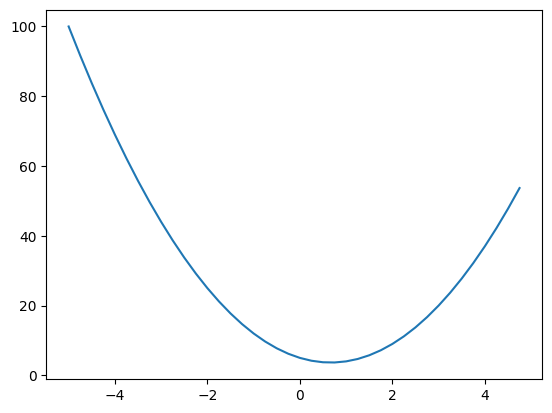

In [23]:
xs = np.arange(-5, 5, 0.25)
xs
fs = f(xs)
plt.plot(xs, fs)

In [ ]:
h = 1e-5
(f(3 + h) - f(3)) / h   #gives the slope of the function at x = 3, which is the derivative of f at that point.

14.00003000000538

In [ ]:
h = 0.0001
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
a += h   # for deriving with respect to a, we need to change the value of a by a small amount h and see how the output changes.
d_a = (a*b + c - d) / h   # this is the derivative of d with respect to a, which is basically b.
print(d)
print(a*b + c)
print(d_a)


3.999699999999999


-3.000000000010772

In [39]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self._label = label
        self.grad = 0.0

    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out
    def __mul__(self, other):
        return Value(self.data * other.data, (self, other), '*')
    def __pow__(self, other):
        return Value(self.data ** other.data, (self, other), '**')
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        return Value(t, (self,), 'tanh')

In [30]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e._label='e' # a.__add__(b)
d = e + c; d._label='d'   # (a.__mul__(b)).__add__(c)
d._prev # gives the child nodes of d which are a*b and c.
d._op # gives the operation that was used to create d.
f = Value(-2.0, label='f')
L = d * f; L._label='L'

In [2]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR means left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in graph, create a rectangle ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n._label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect the op node to this value node
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

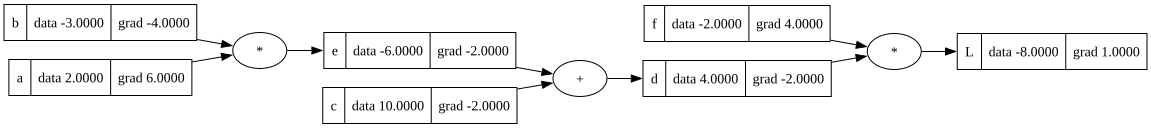

In [35]:
draw_dot(L)

In [ ]:
# now we will implement the backpropagation to get the grad of L with respect to d, f, e, c, b, a. 
# We will use the chain rule to do this. We will start from L and go backwards to a, b, c, d, f.
# manual gradient
L.grad = 1.0
# dL/dd = f as L = d * f
# dL/df = d as L = d * f
f.grad = d.data
d.grad = f.data
# dL/dc = dL/dd * dd/dc, here dd/dc = 1 as d = e + c
c.grad = d.grad * 1.0
e.grad = d.grad * 1.0
# dL/db = dL/de * de/db, here de/db = a as e = a * b
b.grad = e.grad * a.data
a.grad = e.grad * b.data

In [13]:
# doing it for tanh activation function 
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1._label='x1w1'
x2w2 = x2 * w2; x2w2._label='x2w2'
x1x2w1w2 = x1w1 + x2w2; x1x2w1w2._label='x1x2w1w2'
n = x1x2w1w2 + b; n._label='n'
o = n.tanh(); o._label='o'

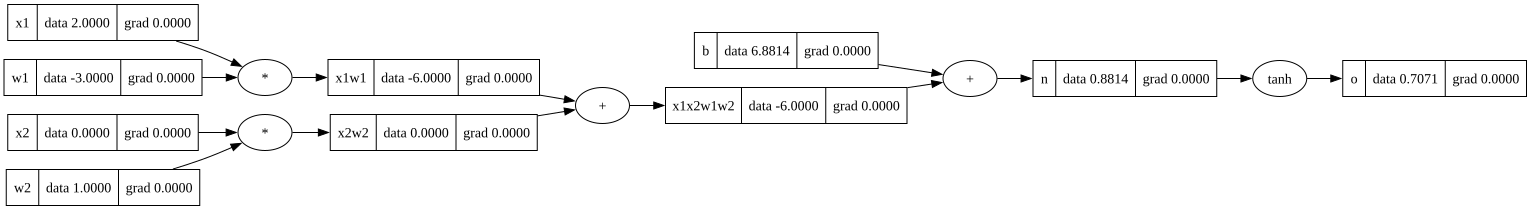

In [14]:
draw_dot(o)

In [15]:
o.grad = 1.0
#do/dn = 1 - tanh(n)^2 the derivative of tanh.
n.grad = (1 - o.data ** 2)
#do/db = do/dn * dn/db, here dn/db = 1 as n = x1x2w1w2 + b
b.grad = n.grad * 1.0
x1x2w1w2.grad = n.grad * 1.0
#do/dx1w1 = do/x1x2w1w2 * dx1x2w1w2/dx1w1, here dx1x2w1w2/dx1w1 = 1 as x1x2w1w2 = x1w1 + x2w2
x1w1.grad = x1x2w1w2.grad * 1.0
x2w2.grad = x1x2w1w2.grad * 1.0
#do/w2 = do/x2w2 * dx2w2/dw2. here dx2w2/dw2 = x2 as x2w2 = x2 * w2
w2.grad = x2w2.grad * x2.data
x2.grad = x2w2.grad * w2.data
x1.grad = x1w1.grad * w1.data
w1.grad = x1w1.grad * x1.data

# we can see a pattern here, for addition its always the local grad of the output, for multiplication its the other input * local grad of the output
# for tanh its 1 - local_output^2 * local grad of the output.

implementing the backward method in the Value class to automate the backpropagation process.



In [16]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self._label = label
        self.grad = 0.0
        self._backward = lambda: None  # function to be called during backpropagation

    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad = out.grad * 1.0
            other.grad = out.grad * 1.0
        out._backward = _backward
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad = out.grad * other.data
            other.grad = out.grad * self.data
        out._backward = _backward
        return out
    def __pow__(self, other):
        return Value(self.data ** other.data, (self, other), '**')
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad = (1 - out.data ** 2)
        out._backward = _backward
        return out

In [17]:
# doing it for tanh activation function 
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1._label='x1w1'
x2w2 = x2 * w2; x2w2._label='x2w2'
x1x2w1w2 = x1w1 + x2w2; x1x2w1w2._label='x1x2w1w2'
n = x1x2w1w2 + b; n._label='n'
o = n.tanh(); o._label='o'

In [18]:
o.grad = 1.0 #setting the first grad to 1.0 as we are starting from the output node.
o._backward() # this will call the backward function of o which will set the grad of n, b, x1x2w1w2
n._backward()
b._backward() # nothing happens as b is a leaf node and has no children.
x1x2w1w2._backward()
x1w1._backward()
x2w2._backward()


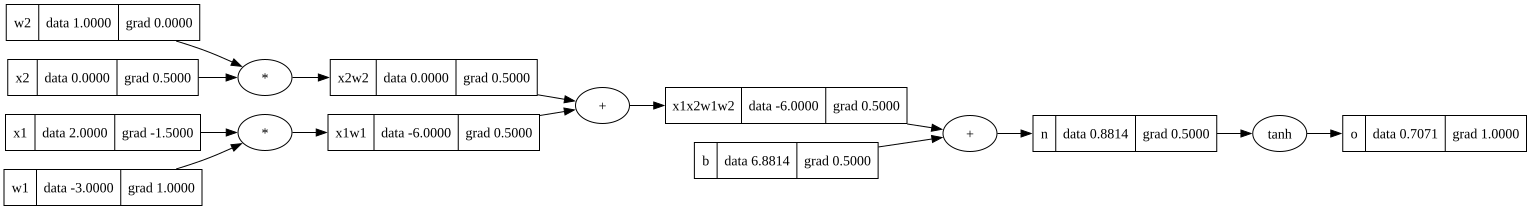

In [19]:
draw_dot(o)

doing topological sorting to automatically call these backwards!!

In [20]:
o.grad = 1.0
topo = [] 
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
for node in reversed(topo):
    node._backward()

putting this in a backward function in class value!!

In [21]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self._label = label
        self.grad = 0.0
        self._backward = lambda: None  # function to be called during backpropagation

    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out
    def __pow__(self, other):
        return Value(self.data ** other.data, (self, other), '**')
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1 - out.data ** 2)
        out._backward = _backward
        return out
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [22]:
#running it again!!
o.backward()

AttributeError: 'Value' object has no attribute 'backward'

But there is a bug when we try to use one node multiple times so we will fix it with the help of adding like self.grad += term and not just self.grad = term

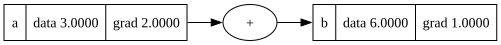

In [23]:
app = Value(3.0, label='a')
b = app + app; b._label='b'
b.backward()
draw_dot(b)

In [31]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self._label = label
        self.grad = 0.0
        self._backward = lambda: None  # function to be called during backpropagation

    def __repr__(self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)  #when adding a constant to a Value, we need to convert the constant to a Value. like a + 2.
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward
        return out
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)  #a * 2, but what about 2 * a? we need to implement __rmul__ for that.
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def __rmul__(self, other): # other * self
        return self * other  # this will call __mul__ method, which will handle the case when other is a constant. and for addition, we need to implement __radd__ for that.
    def __radd__(self, other): # other + self
        return self + other
    def __sub__(self, other): # self - other
        return self + (- other) 
    def __truediv__(self, other): # self / other
        return self * other**-1  # this will call __pow__ method, as a/ b is same as a * (b ** -1)
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data ** other, (self,), '**')
        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad  # chain rule, derivative of x^n is n*x^(n-1)
        out._backward = _backward
        return out

    def exp(self):
        n = self.data
        out = Value(math.exp(n), (self,), 'exp')
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1 - out.data ** 2) * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [32]:
#doing grad thing in pytorch
import torch

In [33]:
torch.tensor([[1.0, 2.0, 3.0], [4, 5, 6]])

tensor([[1., 2., 3.],
        [4., 5., 6.]])

In [34]:
x1 = torch.tensor([2.0]).double(); x1.requires_grad=True     #.double()makes float32 to float64, more decimal precision.
x2 = torch.tensor([0.0]).double(); x2.requires_grad=True
w1 = torch.tensor([-3.0]).double(); w1.requires_grad=True
w2 = torch.tensor([1.0]).double(); w2.requires_grad=True
b = torch.tensor([6.8813735870195432]).double(); b.requires_grad=True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)
print(o.data.item())
print(x1.grad)
o.backward()
print(x1.grad)  # prints the gradient of o with respect to x1
print(x2.grad.item())  # .item() gives the value of the tensor as a python float64 and just grad or data gives the tensor object itself.

0.7071066904050358
None
tensor([-1.5000], dtype=torch.float64)
0.5000001283844369


In [35]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(np.random.uniform()) for _ in range(nin)]
        self.b = Value(np.random.uniform())

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)  # sum of all the weights * inputs + bias
        out = act.tanh()  # activation function
        return out
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    def __call__(self, x):
        out = [n(x) for n in self.neurons]
        return out[0] if len(out) == 1 else out
    def parameters(self):
        #return [p for neuron in self.neurons for p in neuron.parameters()]
        params = []
        for neuron in self.neurons:
            params.extend(neuron.parameters())
        return params

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])  # 3 inputs, 2 hidden layers with 4 neurons each, and 1 output
n(x)
#draw_dot(n(x))

Value(data=0.9779669873534002)

In [36]:
xs = [
    [2.0, 3.0, -1.0], 
    [3.0, -1.0, 0.5], 
    [0.5, 1.0, 1.0], 
    [1.0, 1.0, -1.0]]
ys = [1.0, -1.0, -1.0, 1.0]

In [84]:
# we need the ypred to get close to ys so first we need to find how far off it is so we will calcuate mean squared error loss function.
for k in range(20000):
    ypred = [n(x) for x in xs] #doing it again to get the new predictions after updating the weights and biases.
    loss = sum((yout - yt)**2 for yout, yt in zip(ypred, ys))
    for p in n.parameters():
        p.grad = 0.0  # reset the gradients to zero before calculating the new gradients for this iteration.
    loss.backward()  # this will calculate the gradients of all the parameters in the network with respect to the loss.
    for p in n.parameters():
        p.data += -0.9 * p.grad  # update the weights and biases using gradient descent with learning rate 0.05
    print(k, loss.data)

0 1.2192413955458264e-06
1 1.2191968688041978e-06
2 1.2191523452913308e-06
3 1.2191078250069963e-06
4 1.2190633079508147e-06
5 1.2190187941219288e-06
6 1.2189742835203955e-06
7 1.2189297761460013e-06
8 1.2188852719981313e-06
9 1.2188407710763906e-06
10 1.2187962733807705e-06
11 1.2187517789110003e-06
12 1.21870728766591e-06
13 1.2186627996457742e-06
14 1.2186183148503713e-06
15 1.2185738332789713e-06
16 1.218529354931544e-06
17 1.2184848798069829e-06
18 1.2184404079059163e-06
19 1.2183959392274324e-06
20 1.2183514737717623e-06
21 1.2183070115379567e-06
22 1.2182625525256347e-06
23 1.2182180967349858e-06
24 1.2181736441655722e-06
25 1.2181291948162434e-06
26 1.2180847486873592e-06
27 1.2180403057784417e-06
28 1.2179958660890529e-06
29 1.2179514296192613e-06
30 1.217906996368263e-06
31 1.2178625663358343e-06
32 1.217818139521607e-06
33 1.2177737159250373e-06
34 1.217729295546038e-06
35 1.2176848783843467e-06
36 1.2176404644392025e-06
37 1.217596053711063e-06
38 1.2175516461985222e-06
39 

In [77]:
n.layers[0].neurons[0].w[0].grad  # this will give the gradient of the first weight of the first neuron of the first layer with respect to the loss.

7.259324154499946e-08

In [86]:
ypred

[Value(data=0.9995822625619707),
 Value(data=-0.9996235549757208),
 Value(data=-0.999562374261707),
 Value(data=0.9995577956349686)]